# Tessera neural codec — demo

A learned pyramidal RVQ codec for [Tessera](https://github.com/ucam-eo/geotessera)
embedding tiles (128 bands, 10 m grid). One encode serves the whole
rate–distortion front: the packet is stored at full depth and *truncating
RVQ levels at decode time is the rate control*, so a 0.19 b/px preview and
a 1.12 b/px reconstruction come from the same bytes.

| the packet carries | |
|---|---|
| per-tier code indices | 3 tiers on a 64 px window: 1, 16 and 256 cells |
| the patch mean | 128 bands x 6 bits, charged at every rate |
| an optional refinement | fine-tier residual, off by default |

**Decoding needs no GPU and no extras** — this notebook runs on CPU in
about a minute. Full contract: `docs/TESSERA_RELEASE.md`.

In [1]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt
import torch

sys.path.insert(0, "..")                    # georvq (run from notebooks/)
from georvq.tessera import (load, encode_tile, decode_tile, prep,
                            requantize, to_windows, from_windows)
from georvq.metrics import centered_cos

BUNDLE = os.environ.get("GEORVQ_TESSERA_BUNDLE",
                        "/data/georvq-releases/tessera-beta-v1/bundle")
DEVICE = "cpu"          # a GPU is not needed; set "cuda:0" if you have one
YEAR, LON, LAT = 2024, 40.65, 56.55         # a registry tile (Vladimir, RU)
CROP = 512                                  # px; 8x8 = 64 codec windows

R = load(BUNDLE, device=DEVICE)
print("bitstream_id :", R.bundle["bitstream_id"])
print("tiers        :", R.bundle["tiers"])
print("mean channel :", R.bundle["mean_channel"])
print("refinement   :", R.bundle["refinement"],
      "| on by default:", R.bundle["refine_by_default"])

/home/ali/projects/georvq/.claude/worktrees/tessera-notebooks/notebooks/../georvq/model/tokenizer.py:47: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.vit = nn.TransformerEncoder(layer, depth)


bitstream_id : b7e303ce20aca88e
tiers        : ['1:512:256:20', '4:512:256:20', '16:256:256:20']
mean channel : {'bits_per_band': 6, 'bits_per_window': 768}
refinement   : {'tier': 2, 'bits': 1, 'quantizer': 'lloyd', 'sigma': 2.0, 'rotate_seed': 0} | on by default: False


## 1. A tile, straight from `geotessera`

No chip store, no preprocessing of ours: `geotessera` hands back int8
codes and a per-pixel scale plane, and that is exactly what the codec
takes. (`georvq.tessera.prep` accepts either `(H, W, bands)` as returned
here or `(bands, H, W)`; both land on identical tensors.)

In [2]:
import geotessera
gt = geotessera.GeoTessera()

t0 = time.time()
q = np.load(gt.registry.fetch(year=YEAR, lon=LON, lat=LAT))
s = np.load(gt.registry.fetch(year=YEAR, lon=LON, lat=LAT, is_scales=True))
print(f"fetched in {time.time()-t0:.0f}s")
print("embedding", q.shape, q.dtype, " scales", s.shape, s.dtype)

q, s = q[:CROP, :CROP], s[:CROP, :CROP]     # one crop, to keep the demo quick
x, valid = prep(q, s, device=DEVICE)        # (1, 128, CROP, CROP) model space
print("model space", tuple(x.shape), "| valid", f"{valid.float().mean():.1%}")

fetched in 0s
embedding (1128, 641, 128) int8  scales (1128, 641) float32
model space (1, 128, 512, 512) | valid 100.0%


## 2. What 128 bands look like

There is no natural RGB for an embedding field, so everything below is
projected through the *same* PCA basis — fitted on the original — which
keeps originals and reconstructions comparable to each other.

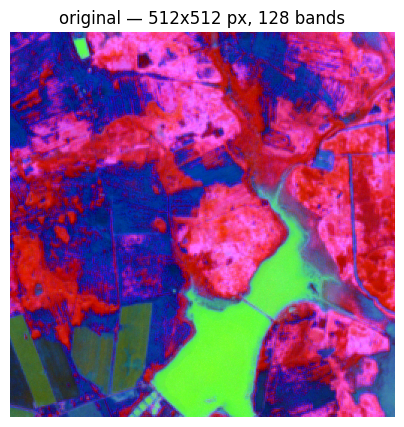

In [3]:
def pca_basis(t):
    v = t[0].reshape(t.shape[1], -1).T.float()
    v = v - v.mean(0)
    return torch.linalg.svd(v[::7], full_matrices=False)[2][:3].T

def to_rgb(t, basis):
    v = t[0].reshape(t.shape[1], -1).T.float() @ basis
    lo, hi = torch.quantile(v, torch.tensor([0.02, 0.98]), dim=0)
    v = ((v - lo) / (hi - lo)).clamp(0, 1)
    return v.reshape(t.shape[2], t.shape[3], 3).numpy()

BASIS = pca_basis(x)
plt.figure(figsize=(5, 5)); plt.imshow(to_rgb(x, BASIS)); plt.axis("off")
plt.title(f"original — {CROP}x{CROP} px, 128 bands"); plt.show()

## 3. Encode once

`encode_tile` cuts the tile into 64 px windows, encodes each at **full
depth**, and returns the packets plus the window grid. Whole windows
only: a tile that does not divide evenly is cropped rather than padded,
because padding invents data the encoder would then spend rate on.

In [4]:
t0 = time.time()
packets, grid = encode_tile(R, q, s, batch=32)
print(f"encoded {len(packets)} windows in {time.time()-t0:.1f}s  (grid {grid})")

p = packets[0]
print("\nper window:")
for i, idx in enumerate(p.indices):
    print(f"  tier {i}: indices {idx.shape}  {idx.dtype}")
print(f"  mean   : {p.mean.shape} {p.mean.dtype}  <- the side channel")
print(f"  refine : {p.refinements}")

encoded 64 windows in 1.5s  (grid (1, 8, 8))

per window:
  tier 0: indices (1, 20)  int64
  tier 1: indices (16, 20)  int64
  tier 2: indices (256, 20)  int64
  mean   : (128,) float32  <- the side channel
  refine : None


## 4. The rate ladder — one encode, every rate

`depths` truncates RVQ levels at decode time. The same `packets` object
serves every row below; nothing is re-encoded.

`ccos` is the centred cosine, and it is the honest one here: the patch
mean is transmitted, so plain cosine is inflated by a channel that is
already paid for.

The numbers below are for **this one tile**, not the release figures: `docs/TESSERA_RELEASE.md` reports the ladder over a held-out set, where full depth is ccos 0.807 rather than the ~0.93 an easy tile gives.

In [5]:
LADDER = [(20, 0, 0), (20, 20, 0), (20, 20, 1), (20, 20, 3), (20, 20, 6),
          (20, 20, 20)]
LOSSLESS = 672.0        # b/px, measured by analysis/data_probe.py

# Reported in the units the tessera-vq paper uses, so the two codecs are
# directly comparable: relative L2 (median, as in its Table 2) and R^2,
# both scale-free, plus the centred cosine this project tracks.
def metrics(out, ref, vmask):
    o, r = requantize(out), requantize(ref)          # -> source units
    cc = float(centered_cos(out, ref, vmask))
    e = (o - r).pow(2).sum(1).sqrt()
    rel = (e / r.pow(2).sum(1).sqrt().clamp_min(1e-9))[vmask]
    r2 = 1 - float((o - r).pow(2).sum() / (r - r.mean()).pow(2).sum())
    return cc, float(rel.median()), r2

recons, rows = {}, []
for d in LADDER:
    out = decode_tile(R, packets, grid, depths=list(d), batch=32)
    recons[d] = out
    h, w = out.shape[2], out.shape[3]
    cc, rel, r2 = metrics(out, x[:, :, :h, :w], valid[:, :h, :w])
    rows.append((d, R.bpp(list(d)), cc, rel, r2))

print(f"{'tuple':>10} {'b/px':>8} {'vs lossless':>12} {'ccos':>8} "
      f"{'rel L2':>8} {'R^2':>8}")
for d, bpp, cc, rel, r2 in rows:
    print(f"{'-'.join(map(str,d)):>10} {bpp:8.3f} {LOSSLESS/bpp:11.0f}x "
          f"{cc:8.4f} {rel:8.4f} {r2:8.4f}")

     tuple     b/px  vs lossless     ccos   rel L2      R^2
    20-0-0    0.227        2966x   0.7509   0.3332   0.8720
   20-20-0    0.852         789x   0.8525   0.2675   0.9193
   20-20-1    1.352         497x   0.8662   0.2578   0.9259
   20-20-3    2.352         286x   0.8885   0.2402   0.9373
   20-20-6    3.852         174x   0.9038   0.2258   0.9453
  20-20-20   10.852          62x   0.9290   0.1976   0.9587


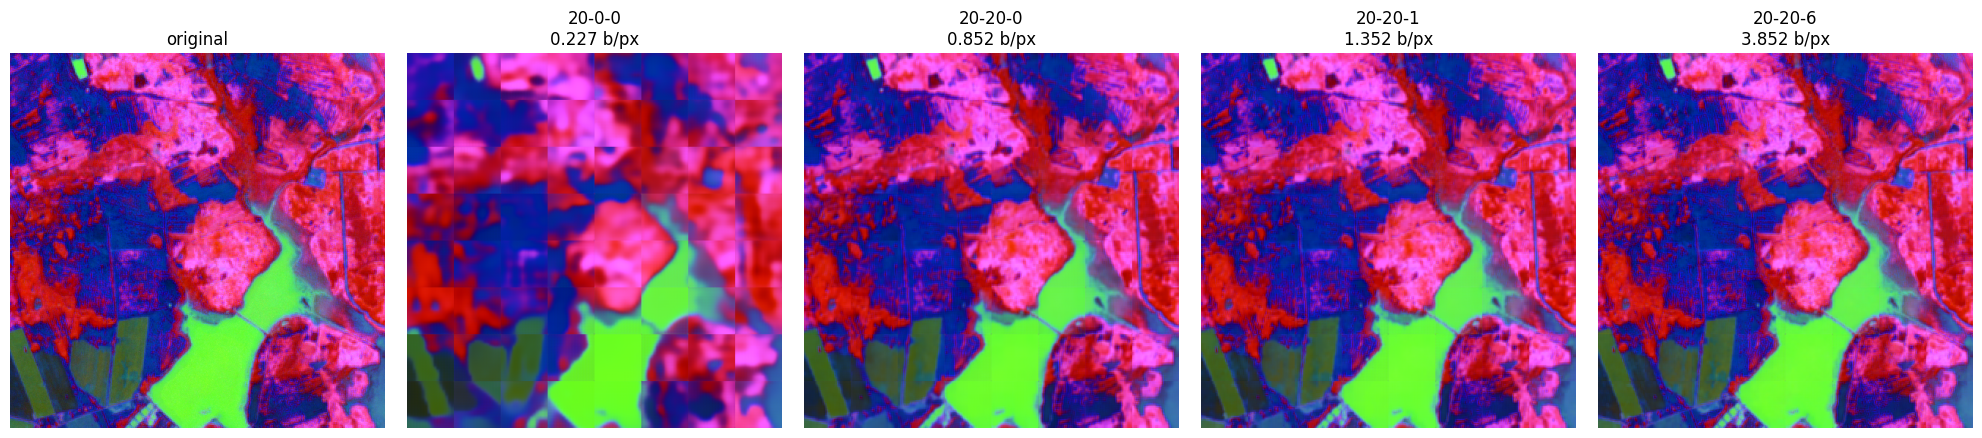

In [6]:
show = [(20, 0, 0), (20, 20, 0), (20, 20, 1), (20, 20, 6)]
fig, ax = plt.subplots(1, len(show) + 1, figsize=(4 * (len(show) + 1), 4.2))
ax[0].imshow(to_rgb(x, BASIS)); ax[0].set_title("original"); ax[0].axis("off")
for a, d in zip(ax[1:], show):
    a.imshow(to_rgb(recons[d], BASIS)); a.axis("off")
    a.set_title(f"{'-'.join(map(str,d))}\n{R.bpp(list(d)):.3f} b/px")
plt.tight_layout(); plt.show()

## 5. The transmitted mean

Tessera vectors are not unit-norm, and the per-window mean is most of a
window's energy — cheap to send and worth far more per bit than extra
pyramid depth. So the codec subtracts it, codes what is left, and adds it
back, with both encoder and decoder conditioned on it.

It is **charged at every rate**, which matters most at the bottom of the
ladder where it is the majority of the bitstream. Quantizing it costs
almost nothing against sending it exactly.

In [7]:
side = R.side_bits
print(f"mean channel: {side:.0f} bits/window = {side/64**2:.4f} b/px")
for d in [(20, 0, 0), (20, 20, 0), (20, 20, 20)]:
    tot = R.bpp(list(d))
    print(f"  at {'-'.join(map(str,d)):>9}: {side/64**2/tot:5.1%} of the bitstream")

# what the quantization of that channel costs, end to end
mu = R.model.patch_mean(x, valid)
print(f"\nmean vector: {tuple(mu.shape)}, quantized to "
      f"{R.mean_channel.bits} bits/band against shipped per-band constants")
err = (R.mean_channel.round_trip(mu.cpu().numpy()) - mu.cpu().numpy())
print(f"round-trip error: max {np.abs(err).max():.5f}, "
      f"rms {np.sqrt((err**2).mean()):.5f}")

mean channel: 768 bits/window = 0.1875 b/px
  at    20-0-0: 82.8% of the bitstream
  at   20-20-0: 22.0% of the bitstream
  at  20-20-20:  1.7% of the bitstream

mean vector: (1, 128), quantized to 6 bits/band against shipped per-band constants
round-trip error: max 0.00547, rms 0.00221


## 6. The optional refinement

After all 20 levels a tier still has a residual. Coding it at ~1 bit per
dimension in a fixed random rotation buys part of the gap back to the
un-quantized ceiling, with **no extra trained codebooks** — the whole
"codebook" is a seed plus a Lloyd table fitted once.

It is **off by default here**, unlike the AlphaEarth release's coarse
sidecar, and the reason is worth knowing: *which* tier holds recoverable
slack is a property of the model, not of the architecture. On this model
the coarse tier returns nothing and the fine tier returns a lot — but the
fine tier has 256 cells, so it costs 128x more.

In [8]:
full = [20, 20, 20]
pk_r, grid_r = encode_tile(R, q, s, batch=32, refine=True)
out_r = decode_tile(R, pk_r, grid_r, depths=full, batch=32)
xc = x[:, :, :out_r.shape[2], :out_r.shape[3]]
vc = valid[:, :out_r.shape[2], :out_r.shape[3]]

base_cc = float(centered_cos(recons[tuple(full)], xc, vc))
ref_cc = float(centered_cos(out_r, xc, vc))
_, base_l2, base_r2 = metrics(recons[tuple(full)], xc, vc)
_, ref_l2, ref_r2 = metrics(out_r, xc, vc)
# the model works on 64px windows, so the ceiling is measured there and
# stitched back, giving a tile-shaped result comparable to the decodes
xw, vw, gr = to_windows(x, valid, R.window)
ceil = from_windows(R.model.eval_ceiling(xw, valid=vw), gr, R.window)
ceil_cc = float(centered_cos(ceil[:, :, :xc.shape[2], :xc.shape[3]], xc, vc))

print(f"{'':>22} {'b/px':>8} {'ccos':>8} {'rel L2':>8} {'R^2':>8}")
print(f"{'RVQ x20':>22} {R.bpp(full):8.3f} {base_cc:8.4f} {base_l2:8.4f} {base_r2:8.4f}")
print(f"{'+ refinement':>22} {R.bpp(full, refine=True):8.3f} {ref_cc:8.4f} {ref_l2:8.4f} {ref_r2:8.4f}")
print(f"{'un-quantized ceiling':>22} {'-':>8} {ceil_cc:8.4f} {'-':>8} {'-':>8}")
gap = (ref_cc - base_cc) / max(ceil_cc - base_cc, 1e-9)
print(f"\ngap to the ceiling closed: {gap:.0%} "
      f"for +{R.bpp(full, refine=True)-R.bpp(full):.2f} b/px")

                           b/px     ccos   rel L2      R^2
               RVQ x20   10.852   0.9290   0.1976   0.9587
          + refinement   26.852   0.9417   0.1806   0.9655
  un-quantized ceiling        -   0.9510        -        -

gap to the ceiling closed: 58% for +16.00 b/px


## 7. Against tessera-vq

[tessera-vq](https://github.com/sk818/tessera-vq) (Yang, Feng & Keshav,
*Using Residual Vector Quantization to Compress Spatially Auto-correlated
Geo-Foundation Models*) is the deployed point of comparison: per-tile
two-stage RVQ, a stage-1 codebook of prototypes plus a stage-2 residual
codebook, with two byte-aligned index planes.

Run here **exactly as that paper specifies**, which is worth being
careful about because the obvious shortcuts all get it wrong:

* **Euclidean k-means on the embeddings, not cosine.** Their §3 measures
  magnitude as carrying signal and cosine k-means as 3.4x worse, and
  rejects it. Benchmarking against a cosine variant would be scoring
  them on a configuration they explicitly discarded.
* **gzip on the stage-1 plane, not RLE.** Their §5.1 finds a plain
  raster scan beats Hilbert and Morton at this scale, and that gzip on
  the map beats space-filling-curve + RLE by 2.1-2.6x. They discard RLE.
* **The stage-2 plane does not compress** -- it is spatially white and
  ships raw at 1 byte/pixel.
* **Metrics are relative L2 and R-squared**, both scale-free (their
  Table 2). We report ours the same way here.

**Same patch, same pixels.** Their codebook cost amortizes as 1/p^2, so
tile size is part of their rate and the comparison is only fair at a
matched one. Both codecs here see the identical 512x512 region, which is
their recommended p=512: tessera-vq fits one per-tile codebook over it,
and this codec tiles it into 8x8 windows of 64 px and stitches them back.

Their recommended configuration is p=512, k1=20, k2=256 at
**1.38 bytes/pixel = 11.0 b/px**. Our full depth is 10.85 b/px, so this
is close to a matched-rate comparison rather than two curves fitted at
different budgets.

In [9]:
import gzip
from tessera_vq.rvq_large import rvq_reconstruct_large

# their space: dequantized embeddings, magnitude kept (L2 k-means)
tile = requantize(x)[0, :, :CROP, :CROP].permute(1, 2, 0).numpy()
flat = tile.reshape(-1, 128)

def tvq(k1, k2, p=CROP):
    r = rvq_reconstruct_large(tile, k1, k2, seed=0)
    rec = np.asarray(r.recon).reshape(-1, 128)
    err = np.linalg.norm(flat - rec, axis=1)
    rel = float(np.median(err / np.maximum(np.linalg.norm(flat, axis=1), 1e-9)))
    r2 = 1 - float(((flat - rec) ** 2).sum() / ((flat - flat.mean(0)) ** 2).sum())
    idx1 = np.asarray(r.indices1).astype(np.uint8).tobytes()
    bpp = (len(gzip.compress(idx1, 9)) / p ** 2      # stage-1, gzip (their 5.1)
           + 1.0                                     # stage-2, raw byte plane
           + (k1 + k2) * 128 / p ** 2) * 8           # both codebooks, int8
    return bpp, rel, r2

tv = [(f"k1={k1} k2={k2}", *tvq(k1, k2)) for k1, k2 in
      [(20, 256), (32, 256), (128, 256)]]

print(f"{'tessera-vq':>14} {'b/px':>8} {'rel L2':>8} {'R^2':>8}")
for n, b, rel, r2 in tv:
    star = "   <- recommended" if n.startswith("k1=20") else ""
    print(f"{n:>14} {b:8.3f} {rel:8.4f} {r2:8.4f}{star}")
print(f"\n{'this codec':>14} {'b/px':>8} {'rel L2':>8} {'R^2':>8}")
for d, bpp, cc, rel, r2 in rows:
    print(f"{'-'.join(map(str, d)):>14} {bpp:8.3f} {rel:8.4f} {r2:8.4f}")

    tessera-vq     b/px   rel L2      R^2
  k1=20 k2=256   11.091   0.2532   0.8038   <- recommended
  k1=32 k2=256   11.686   0.2489   0.8099
 k1=128 k2=256   13.667   0.2341   0.8326

    this codec     b/px   rel L2      R^2
        20-0-0    0.227   0.3332   0.8720
       20-20-0    0.852   0.2675   0.9193
       20-20-1    1.352   0.2578   0.9259
       20-20-3    2.352   0.2402   0.9373
       20-20-6    3.852   0.2258   0.9453
      20-20-20   10.852   0.1976   0.9587


### Rate-distortion, on their metrics

The paper reports R-squared ~0.79 and median relative L2 ~0.18 across a
ten-tile sweep; a single tile will not land exactly there (its between-tile
R-squared s.d. is ~0.09), so read the *shapes*, and read the matched-rate
point rather than the endpoints.

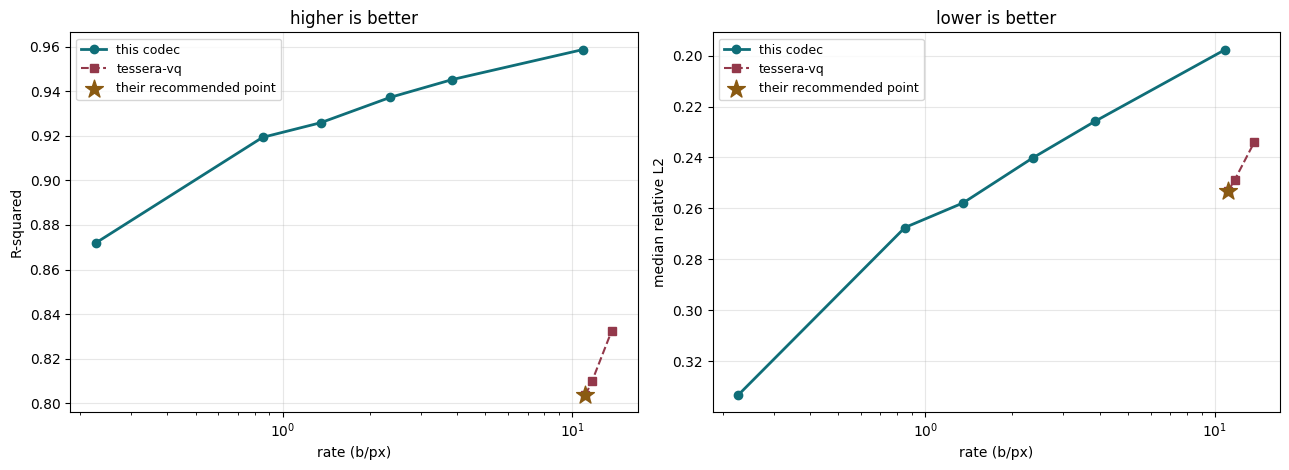

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ob = [r[1] for r in rows]

for a, i, lab, inv in ((ax[0], 4, "R-squared", False),
                       (ax[1], 3, "median relative L2", True)):
    a.plot(ob, [r[i] for r in rows], "o-", lw=2, color="#0f6e78",
           label="this codec")
    a.plot([t[1] for t in tv], [t[3 if i == 4 else 2] for t in tv], "s--",
           color="#93384a", label="tessera-vq")
    a.scatter([tv[0][1]], [tv[0][3 if i == 4 else 2]], s=180, marker="*",
              color="#8a5a12", zorder=5, label="their recommended point")
    a.set(xscale="log", xlabel="rate (b/px)", ylabel=lab)
    a.grid(alpha=0.3); a.legend(fontsize=9)
    if inv:
        a.invert_yaxis()
ax[0].set_title("higher is better"); ax[1].set_title("lower is better")
plt.tight_layout(); plt.show()

### At matched rate

Their recommended 11.0 b/px against our 10.85 b/px full depth -- the two
codecs at, for practical purposes, the same budget.

                   b/px   rel L2      R^2
    tessera-vq   11.091   0.2532   0.8038
    this codec   10.852   0.1976   0.9587


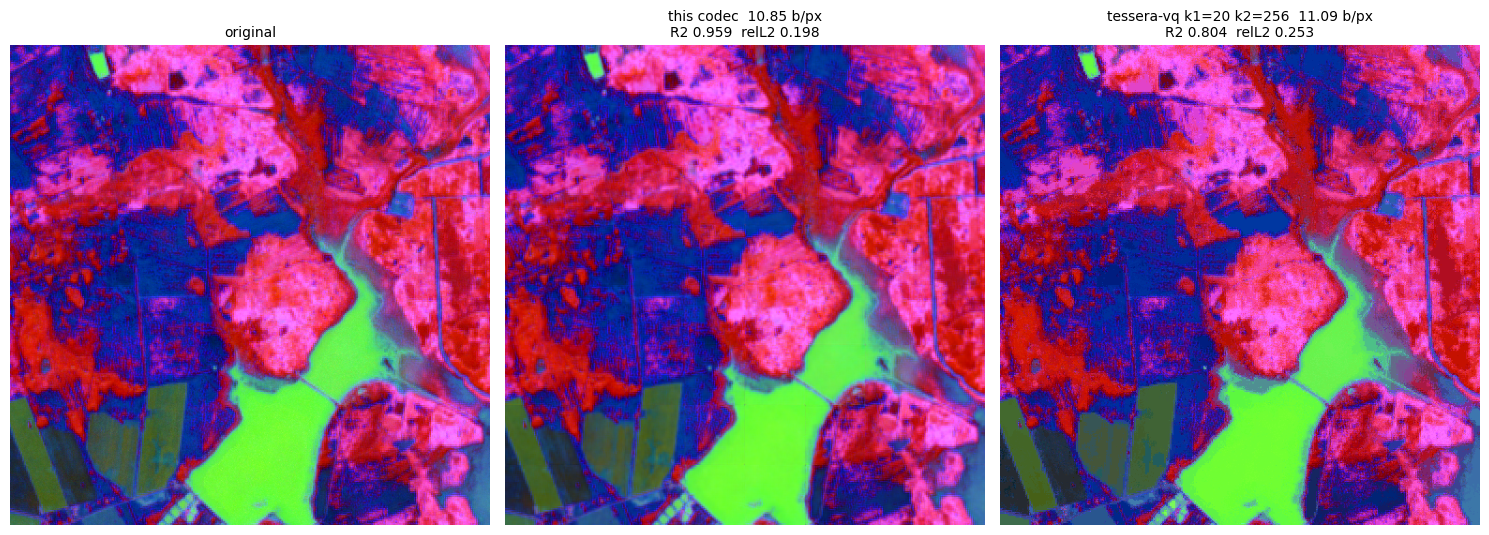

In [11]:
rec_bpp, rec_rel, rec_r2 = tv[0][1], tv[0][2], tv[0][3]
ours = rows[-1]                                   # 20-20-20, full depth
r_tv = rvq_reconstruct_large(tile, 20, 256, seed=0)
XNORM = R.model.source.XNORM        # source units -> model space, for the
tv_t = torch.from_numpy(np.asarray(r_tv.recon).astype(np.float32)
                        ).permute(2, 0, 1)[None] / XNORM   # shared PCA basis

print(f"{'':>14} {'b/px':>8} {'rel L2':>8} {'R^2':>8}")
print(f"{'tessera-vq':>14} {rec_bpp:8.3f} {rec_rel:8.4f} {rec_r2:8.4f}")
print(f"{'this codec':>14} {ours[1]:8.3f} {ours[3]:8.4f} {ours[4]:8.4f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 5.2))
for a, t, ttl in (
        (ax[0], x, "original"),
        (ax[1], recons[ours[0]],
         f"this codec  {ours[1]:.2f} b/px\nR2 {ours[4]:.3f}  relL2 {ours[3]:.3f}"),
        (ax[2], tv_t,
         f"tessera-vq k1=20 k2=256  {rec_bpp:.2f} b/px\n"
         f"R2 {rec_r2:.3f}  relL2 {rec_rel:.3f}")):
    a.imshow(to_rgb(t, BASIS)); a.axis("off"); a.set_title(ttl, fontsize=10)
plt.tight_layout(); plt.show()

## 7. Back to source units

`requantize` undoes the model's internal rescaling, and with the scale
plane it also returns int8 codes on Tessera's own quantization grid — so
a reconstruction can be written back in the layout it arrived in.

In [12]:
orig_units = requantize(recons[(20, 20, 6)])
_, codes = requantize(recons[(20, 20, 6)], s[:orig_units.shape[2],
                                             :orig_units.shape[3]])
print("float, source units:", tuple(orig_units.shape), orig_units.dtype)
print("int8, source grid  :", tuple(codes.shape), codes.dtype)

float, source units: (1, 128, 512, 512) torch.float32
int8, source grid  : (1, 128, 512, 512) torch.int8


## Wrap-up

- **One encode, every rate.** Truncate levels at decode; nothing is
  re-encoded, and a deeper decode is a prefix read away.
- **Pick the rate from the task, not the cosine.** On the five downstream
  benchmarks we have (ASTER GED, LUCAS LC/LU, LCMAP LC/LU) this codec is
  *transparent* — indistinguishable from the uncompressed embedding —
  from about 1 b/px, i.e. around `20-20-1`. The upper ladder exists for
  tasks with finer spatial or temporal structure, which those
  point-thematic benchmarks cannot see. If you have such a task, we would
  very much like to hear how it behaves.
- **Cosine does not transfer across sources.** At matched reconstruction
  cosine this codec costs *less* downstream accuracy than the AlphaEarth
  one, because Tessera carries more independent per-pixel variation and
  much of it is weakly correlated with land cover. Do not port a cosine
  target from another embedding field.

Getting the weights, the full rate table and the format contract:
`docs/TESSERA_RELEASE.md`.